<a href="https://colab.research.google.com/github/kulanigayathree/J26-IT-364/blob/model%2FFishing-Zone-Prediction/notebooks/C2_fishing_zone_prediction/C2_2_train_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# C2 – Notebook 2: Train the fishing-zone model

Run this every working session. It loads the datacube from Drive (no mobile data used), trains:

1. **Baselines** – climatology, persistence, and gradient boosting (numbers to beat)
2. **ConvLSTM** – 7 days of ocean data in → fishing probability for the next 1, 2 and 3 days
3. **MC dropout** – 30 forward passes → probability (mean) and uncertainty (std)

Training saves a checkpoint to Drive after every epoch. If Colab disconnects, run all cells again and it
**continues from the last epoch**.

**Turn on the GPU first:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`.

Split by time (never random): train 2017–2021, validate 2022, test 2023–2024.

## Step 1 – Connect Drive and settings

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
BASE = '/content/drive/MyDrive/C2_data'
CKPT = f'{BASE}/checkpoints'; os.makedirs(CKPT, exist_ok=True)
OUT  = f'{BASE}/results';     os.makedirs(OUT, exist_ok=True)

Mounted at /content/drive


In [ ]:
import numpy as np, pandas as pd, xarray as xr, time, json
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE, '(turn on the T4 GPU if this says cpu)')
torch.manual_seed(42); np.random.seed(42)

T_IN, LEADS = 7, 3                     # 7 input days, predict days t+1, t+2, t+3
TRAIN = ('2017-01-01', '2021-12-31')
VAL   = ('2022-01-01', '2022-12-31')
TEST  = ('2023-01-01', '2024-12-31')
EPOCHS, BATCH, LR, DROPOUT = 30, 16, 1e-3, 0.2
MC_RUNS = 30
FEATURES = ['sst', 'sst_grad', 'log_chl', 'sla', 'u', 'v', 'cur_speed', 'mld',
            'depth', 'moon_sin', 'moon_cos', 'doy_sin', 'doy_cos']

Device: cpu (turn on the T4 GPU if this says cpu)


## Step 2 – Load the datacube and normalise

In [ ]:
X = xr.open_dataset(f'{BASE}/datacube_0p25.nc').load()
days = pd.DatetimeIndex(X.time.values)
ocean = X['depth'].isel(time=0).notnull().values                 # (H, W) True = sea

# Features -> array (time, channel, H, W); normalise with TRAINING-period statistics only
feat = np.stack([X[v].values for v in FEATURES], axis=1).astype('float32')
tr = (days >= TRAIN[0]) & (days <= TRAIN[1])
mean = np.nanmean(feat[tr], axis=(0, 2, 3), keepdims=True)
std  = np.nanstd(feat[tr],  axis=(0, 2, 3), keepdims=True) + 1e-6
feat = (feat - mean) / std
missing = np.isnan(feat)
feat[missing] = 0.0                                                # land / gaps -> 0 after scaling

label = np.nan_to_num(X['fishing'].values).astype('float32')       # (time, H, W) 0/1
NT, C, H, W = feat.shape
print(f'{NT} days, {C} channels, grid {H}x{W}, sea cells {ocean.sum()}')
print('Fishing rate in training years:', label[tr][:, ocean].mean().round(4))
json.dump({'features': FEATURES, 'mean': mean.ravel().tolist(), 'std': std.ravel().tolist()},
          open(f'{OUT}/normalisation.json', 'w'))

2922 days, 13 channels, grid 40x44, sea cells 1421
Fishing rate in training years: 0.0046


## Step 3 – Samples and data loaders
A sample = days *t-6 … t* as input, labels at *t+1, t+2, t+3* as target. Each sample goes to train / val / test
according to the date of its first target day.

In [ ]:
first = np.arange(T_IN - 1, NT - LEADS)                  # index t (last input day)
tgt_day = days[first + 1]
def idx(period): return first[(tgt_day >= period[0]) & (tgt_day <= period[1])]
idx_tr, idx_va, idx_te = idx(TRAIN), idx(VAL), idx(TEST)
print('samples  train', len(idx_tr), ' val', len(idx_va), ' test', len(idx_te))

FEAT_T, LAB_T = torch.from_numpy(feat), torch.from_numpy(label)
MASK_T = torch.from_numpy(ocean.astype('float32'))

class Windows(torch.utils.data.Dataset):
    def __init__(self, ids): self.ids = ids
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        t = self.ids[i]
        return FEAT_T[t - T_IN + 1: t + 1], LAB_T[t + 1: t + 1 + LEADS], t

dl_tr = torch.utils.data.DataLoader(Windows(idx_tr), batch_size=BATCH, shuffle=True, drop_last=True)
dl_va = torch.utils.data.DataLoader(Windows(idx_va), batch_size=BATCH)
dl_te = torch.utils.data.DataLoader(Windows(idx_te), batch_size=BATCH)

samples  train 1819  val 365  test 729


## Step 4 – Evaluation helper (used for every model)

In [ ]:
def scores(prob, ids):
    # prob: (n, LEADS, H, W) predictions for samples ids. Scores only sea cells.
    rows = []
    for k in range(LEADS):
        y = label[ids + 1 + k][:, ocean].ravel()
        p = np.clip(prob[:, k][:, ocean].ravel(), 1e-6, 1 - 1e-6)
        rows.append({'lead_day': k + 1, 'ROC_AUC': roc_auc_score(y, p),
                     'PR_AUC': average_precision_score(y, p), 'Brier': brier_score_loss(y, p)})
    return pd.DataFrame(rows).round(4)

## Step 5 – Baselines (what the deep model must beat)
* **Climatology** – how often each cell had fishing in the same month during training years
* **Persistence** – average fishing in each cell over the last 7 days ("boats go where they went last week")
* **Gradient boosting** – per-cell model on today's ocean features (no spatial or temporal context)

In [ ]:
results = {}

# Climatology
month_tr = days[tr].month
clim = np.stack([label[tr][month_tr == m].mean(0) for m in range(1, 13)])     # (12, H, W)
def clim_pred(ids):
    return np.stack([np.stack([clim[days[t + 1 + k].month - 1] for k in range(LEADS)]) for t in ids])
results['Climatology'] = scores(clim_pred(idx_te), idx_te)

# Persistence (last 7 days of labels)
def pers_pred(ids):
    p = np.stack([label[t - T_IN + 1: t + 1].mean(0) for t in ids])
    return np.repeat(p[:, None], LEADS, axis=1)
results['Persistence'] = scores(pers_pred(idx_te), idx_te)

# Gradient boosting on per-cell features (sampled for speed)
from sklearn.ensemble import HistGradientBoostingClassifier
rng = np.random.default_rng(0)
def pixel_table(ids, n=None):
    t = np.repeat(ids, ocean.sum()); yy, xx = np.where(ocean)
    yy = np.tile(yy, len(ids)); xx = np.tile(xx, len(ids))
    if n and n < len(t):
        s = rng.choice(len(t), n, replace=False); t, yy, xx = t[s], yy[s], xx[s]
    Xp = feat[t, :, yy, xx]
    return Xp, t, yy, xx
Xp, t_, y_, x_ = pixel_table(idx_tr, n=400_000)
hgb = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=0)
hgb.fit(Xp, label[t_ + 1, y_, x_])
def hgb_pred(ids):
    Xq, tq, yq, xq = pixel_table(ids)
    out = np.zeros((len(ids), LEADS, H, W), 'float32')
    p = hgb.predict_proba(Xq)[:, 1]
    pos = np.searchsorted(ids, tq)
    for k in range(LEADS): out[pos, k, yq, xq] = p     # same per-cell forecast for each lead
    return out
results['GradBoost'] = scores(hgb_pred(idx_te), idx_te)

for name, df in results.items():
    print(f'\n{name} (test 2023-24)'); print(df.to_string(index=False))


Climatology (test 2023-24)
 lead_day  ROC_AUC  PR_AUC  Brier
        1   0.6272  0.2307 0.1349
        2   0.6272  0.2307 0.1349
        3   0.6271  0.2308 0.1350

Persistence (test 2023-24)
 lead_day  ROC_AUC  PR_AUC  Brier
        1   0.8649  0.5914 0.0785
        2   0.8506  0.5659 0.0823
        3   0.8440  0.5526 0.0843

GradBoost (test 2023-24)
 lead_day  ROC_AUC  PR_AUC  Brier
        1   0.6014  0.2032 0.1367
        2   0.6006  0.2034 0.1367
        3   0.6000  0.2032 0.1368


## Step 6 – ConvLSTM model
Two ConvLSTM layers read the 7 days one by one (spatial patterns + how they change), then a small head
outputs 3 probability maps. `Dropout2d` stays active at prediction time for MC dropout.

In [ ]:
class ConvLSTMCell(nn.Module):
    def __init__(self, cin, ch, k=3):
        super().__init__(); self.ch = ch
        self.conv = nn.Conv2d(cin + ch, 4 * ch, k, padding=k // 2)
    def forward(self, x, h, c):
        i, f, o, g = torch.chunk(self.conv(torch.cat([x, h], 1)), 4, 1)
        c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)
        return h, c

class FishZoneNet(nn.Module):
    def __init__(self, cin, hidden=(32, 32), p=DROPOUT, out=LEADS):
        super().__init__()
        self.cells = nn.ModuleList()
        prev = cin
        for ch in hidden:
            self.cells.append(ConvLSTMCell(prev, ch)); prev = ch
        self.drop = nn.Dropout2d(p)
        self.head = nn.Sequential(nn.Conv2d(prev, 32, 3, padding=1), nn.ReLU(),
                                  nn.Dropout2d(p), nn.Conv2d(32, out, 1))
    def forward(self, x):                       # x: (B, T, C, H, W)
        B, T, _, H, W = x.shape
        state = [(x.new_zeros(B, c.ch, H, W), x.new_zeros(B, c.ch, H, W)) for c in self.cells]
        for t in range(T):
            inp = x[:, t]
            for j, cell in enumerate(self.cells):
                h, c = cell(inp, *state[j]); state[j] = (h, c)
                inp = self.drop(h) if j < len(self.cells) - 1 else h
        return self.head(self.drop(inp))       # logits (B, LEADS, H, W)

model = FishZoneNet(C).to(DEVICE)
print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')

Parameters: 135,171


## Step 7 – Train (resumes automatically)
Loss = binary cross-entropy on sea cells only, with extra weight on fishing cells because they are rare.
When predicting, that extra weight is mathematically removed again, so the outputs are calibrated probabilities.
The best epoch (highest validation PR-AUC) is kept as `best.pt`.

epoch  1/30  loss 0.5315  val PR-AUC 0.1784  ROC-AUC 0.6821  (458s)  *best*
epoch  2/30  loss 0.4032  val PR-AUC 0.1837  ROC-AUC 0.7029  (444s)  *best*
epoch  3/30  loss 0.3513  val PR-AUC 0.1889  ROC-AUC 0.7133  (441s)  *best*
epoch  4/30  loss 0.3256  val PR-AUC 0.1871  ROC-AUC 0.7229  (441s)
epoch  5/30  loss 0.3026  val PR-AUC 0.1835  ROC-AUC 0.7192  (442s)
epoch  6/30  loss 0.2872  val PR-AUC 0.1761  ROC-AUC 0.7233  (445s)
epoch  7/30  loss 0.2769  val PR-AUC 0.1989  ROC-AUC 0.7478  (443s)  *best*
epoch  8/30  loss 0.2636  val PR-AUC 0.1794  ROC-AUC 0.7315  (442s)
epoch  9/30  loss 0.2542  val PR-AUC 0.1910  ROC-AUC 0.7318  (442s)
epoch 10/30  loss 0.2444  val PR-AUC 0.1979  ROC-AUC 0.7426  (440s)
epoch 11/30  loss 0.2366  val PR-AUC 0.1925  ROC-AUC 0.7316  (439s)
epoch 12/30  loss 0.2283  val PR-AUC 0.1988  ROC-AUC 0.7330  (439s)
epoch 13/30  loss 0.2205  val PR-AUC 0.1890  ROC-AUC 0.7347  (441s)
epoch 14/30  loss 0.2163  val PR-AUC 0.1854  ROC-AUC 0.7185  (440s)
epoch 15/30  los

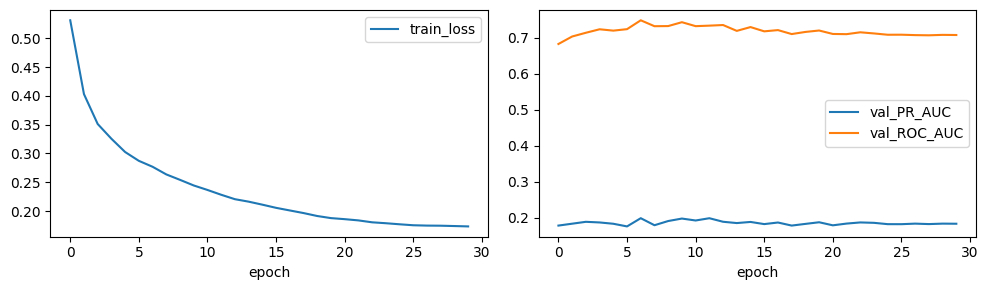

In [ ]:
mask_dev = MASK_T.to(DEVICE)
pos = label[tr][:, ocean].mean()
pos_weight = torch.tensor((1 - pos) / max(pos, 1e-4)).clamp(max=50).to(DEVICE)
LOG_W = torch.log(pos_weight)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)

def masked_loss(logits, y):
    l = F.binary_cross_entropy_with_logits(logits, y, pos_weight=pos_weight, reduction='none')
    m = mask_dev.expand_as(l)
    return (l * m).sum() / m.sum()

@torch.no_grad()
def predict(dl, mc=False, runs=1):
    model.train() if mc else model.eval()            # mc=True keeps dropout ON
    means, stds, ids = [], [], []
    for xb, _, tb in dl:
        xb = xb.to(DEVICE)
        # subtract log(pos_weight): undoes the class weighting so outputs are real probabilities
        ps = torch.stack([torch.sigmoid(model(xb) - LOG_W) for _ in range(runs)])
        means.append(ps.mean(0).cpu()); stds.append(ps.std(0).cpu() if runs > 1 else ps[0].cpu() * 0)
        ids.append(tb)
    return torch.cat(means).numpy(), torch.cat(stds).numpy(), torch.cat(ids).numpy()

start_epoch, best, history = 0, -1.0, []
if os.path.exists(f'{CKPT}/last.pt'):
    ck = torch.load(f'{CKPT}/last.pt', map_location=DEVICE, weights_only=False)
    model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt']); sched.load_state_dict(ck['sched'])
    start_epoch, best, history = ck['epoch'] + 1, ck['best'], ck['history']
    print(f'Resuming from epoch {start_epoch} (best val PR-AUC so far {best:.4f})')

for ep in range(start_epoch, EPOCHS):
    model.train(); t0 = time.time(); tot = 0
    for xb, yb, _ in dl_tr:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        loss = masked_loss(model(xb), yb)
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        tot += loss.item()
    sched.step()
    pv, _, iv = predict(dl_va)
    va = scores(pv, iv)
    pr = float(va.PR_AUC.mean())
    history.append({'epoch': ep, 'train_loss': float(tot / len(dl_tr)), 'val_PR_AUC': pr, 'val_ROC_AUC': float(va.ROC_AUC.mean())})
    improved = pr > best
    if improved:
        best = pr; torch.save(model.state_dict(), f'{CKPT}/best.pt')
    torch.save({'model': model.state_dict(), 'opt': opt.state_dict(), 'sched': sched.state_dict(),
                'epoch': ep, 'best': best, 'history': history}, f'{CKPT}/last.pt')
    print(f'epoch {ep+1:2d}/{EPOCHS}  loss {tot/len(dl_tr):.4f}  val PR-AUC {pr:.4f}  '
          f'ROC-AUC {va.ROC_AUC.mean():.4f}  ({time.time()-t0:.0f}s){"  *best*" if improved else ""}')

h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
h.plot(x='epoch', y='train_loss', ax=ax[0]); h.plot(x='epoch', y=['val_PR_AUC', 'val_ROC_AUC'], ax=ax[1])
plt.tight_layout(); plt.show()

## Step 8 – Test with MC dropout uncertainty and compare with baselines

In [ ]:
model.load_state_dict(torch.load(f'{CKPT}/best.pt', map_location=DEVICE))
p_mean, p_std, ids_te = predict(dl_te, mc=True, runs=MC_RUNS)
results['ConvLSTM + MC dropout'] = scores(p_mean, ids_te)

summary = pd.concat({k: v.set_index('lead_day') for k, v in results.items()}, names=['model'])
print(summary.to_string())
summary.to_csv(f'{OUT}/test_scores.csv')
np.savez_compressed(f'{OUT}/test_predictions.npz', mean=p_mean.astype('float16'),
                    std=p_std.astype('float16'), ids=ids_te)

                                ROC_AUC  PR_AUC   Brier
model                 lead_day                         
Climatology           1          0.6272  0.2307  0.1349
                      2          0.6272  0.2307  0.1349
                      3          0.6271  0.2308  0.1350
Persistence           1          0.8649  0.5914  0.0785
                      2          0.8506  0.5659  0.0823
                      3          0.8440  0.5526  0.0843
GradBoost             1          0.6014  0.2032  0.1367
                      2          0.6006  0.2034  0.1367
                      3          0.6000  0.2032  0.1368
ConvLSTM + MC dropout 1          0.6822  0.2576  0.1357
                      2          0.6831  0.2599  0.1357
                      3          0.6827  0.2597  0.1358


## Step 9 – Calibration and maps
**Reliability diagram:** if the model says 30%, fishing should happen about 30% of the time (points near the
diagonal = well calibrated). **Maps:** probability, uncertainty, and what actually happened for one test day.

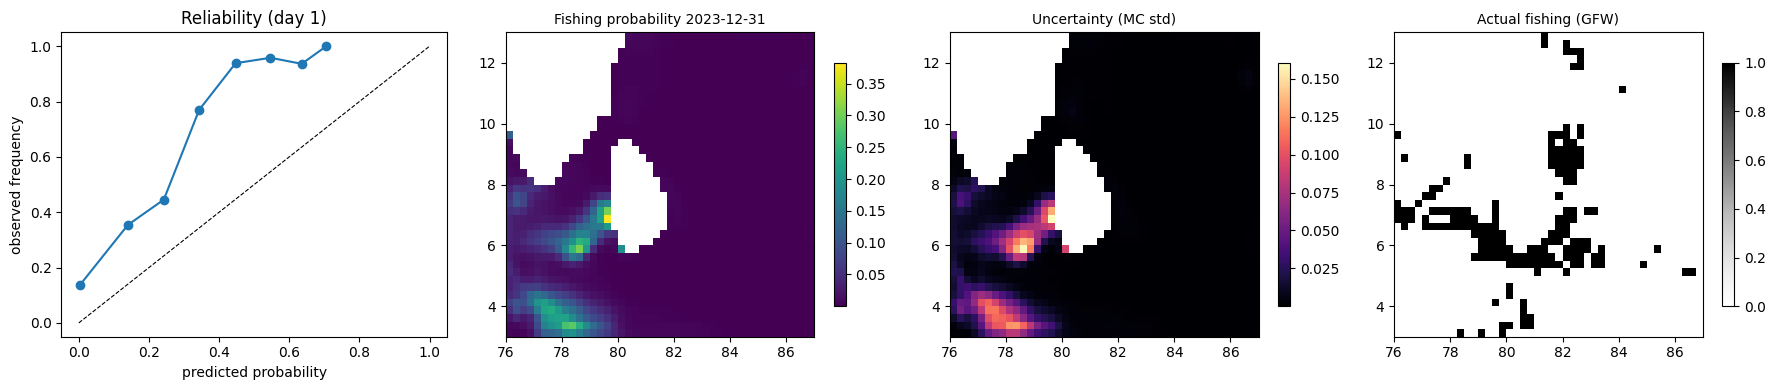

In [ ]:
y = label[ids_te + 1][:, ocean].ravel(); p = p_mean[:, 0][:, ocean].ravel()
bins = np.linspace(0, 1, 11); b = np.digitize(p, bins) - 1
rel = pd.DataFrame({'b': b, 'p': p, 'y': y}).groupby('b').agg(pred=('p', 'mean'), obs=('y', 'mean'), n=('y', 'size'))

d = len(ids_te) // 2                       # a mid-test day
lat, lon = X.latitude.values, X.longitude.values
def show(ax, a, title, cmap):
    im = ax.pcolormesh(lon, lat, np.where(ocean, a, np.nan), cmap=cmap, shading='auto')
    ax.set_title(title, fontsize=10); plt.colorbar(im, ax=ax, shrink=0.8)

fig, ax = plt.subplots(1, 4, figsize=(18, 4))
ax[0].plot([0, 1], [0, 1], 'k--', lw=0.8); ax[0].plot(rel.pred, rel.obs, 'o-')
ax[0].set_xlabel('predicted probability'); ax[0].set_ylabel('observed frequency'); ax[0].set_title('Reliability (day 1)')
when = days[ids_te[d] + 1].date()
show(ax[1], p_mean[d, 0], f'Fishing probability {when}', 'viridis')
show(ax[2], p_std[d, 0], 'Uncertainty (MC std)', 'magma')
show(ax[3], label[ids_te[d] + 1], 'Actual fishing (GFW)', 'Greys')
plt.tight_layout(); plt.savefig(f'{OUT}/example_maps.png', dpi=120); plt.show()